# Taxis NYC · Preparación de datos y modelos

**AIMLF1 · Módulo 2** — Oscar Orantes

Este notebook produce todo lo que usan la API y la app:

| Paso | Qué sale | Dónde se guarda |
|---|---|---|
| 1–3 | Serie horaria de viajes por zona con lags y calendario | memoria |
| 4 | Modelo XGBoost de cuantiles (p10…p90), evaluado por tiempo | `api/modelo_pronostico.ubj` |
| 5 | Filas del 25 de enero al 1 de febrero con sus variables | `api/demanda.parquet` |
| 6 | Segmentación de zonas con K-Means + PCA | `app/data/zonas_segmentadas.csv` |
| 7 | Métricas de la ficha del modelo y del monitoreo | `app/data/*.csv / *.json` |

**Reglas comunes** (iguales para todas las parejas): viajes con hora de inicio en enero de 2024, zona = `PULocationID`,
pronóstico para zonas con ≥ 3,000 viajes, segmentación para zonas con ≥ 500 viajes (sin zonas "Unknown"),
entrenamiento hasta el 24 de enero, prueba del 25 al 31 y pronóstico del 1 de febrero.

In [1]:
import json
import os
import urllib.request
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xgboost as xgb
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

pd.set_option("display.max_columns", 30)
print("xgboost", xgb.__version__, "| pandas", pd.__version__)

RAIZ = Path(".")
DATOS = RAIZ / "datos"
API = RAIZ / "api"
APP_DATA = RAIZ / "app" / "data"
for carpeta in (DATOS, API, APP_DATA):
    carpeta.mkdir(parents=True, exist_ok=True)

URL_VIAJES = "https://d37ci6vzurychx.cloudfront.net/trip-data/yellow_tripdata_2024-01.parquet"
URL_ZONAS = "https://d37ci6vzurychx.cloudfront.net/misc/taxi_zone_lookup.csv"
ARCH_VIAJES = DATOS / "yellow_tripdata_2024-01.parquet"
ARCH_ZONAS = DATOS / "taxi_zone_lookup.csv"

# En Colab los descarga; en local usa los que ya estén en /datos
for url, archivo in ((URL_VIAJES, ARCH_VIAJES), (URL_ZONAS, ARCH_ZONAS)):
    if not archivo.exists():
        print("Descargando", url)
        urllib.request.urlretrieve(url, archivo)

SEMILLA = 42
CUANTILES = np.round(np.arange(0.1, 1.0, 0.1), 1)          # 0.1 … 0.9
NOMBRES_Q = [f"p{int(q * 100)}" for q in CUANTILES]           # p10 … p90
FIN_ENTRENAMIENTO = pd.Timestamp("2024-01-25")                # entrenamiento: < 25 ene
INICIO_PRUEBA, FIN_PRUEBA = pd.Timestamp("2024-01-25"), pd.Timestamp("2024-02-01")
MANANA = pd.Timestamp("2024-02-01")
FERIADOS = [pd.Timestamp("2024-01-15").date()]                # Martin Luther King Jr. Day

xgboost 3.4.1 | pandas 3.0.5


## 1. Cargar los datos

Solo leemos las columnas necesarias. Nos quedamos con los viajes cuya hora de inicio está dentro de enero de 2024
(el archivo trae algunos registros con fechas erróneas de otros años).

In [2]:
COLUMNAS = ["tpep_pickup_datetime", "PULocationID", "trip_distance", "fare_amount", "tip_amount"]
viajes = pd.read_parquet(ARCH_VIAJES, columns=COLUMNAS)
print("Filas en el archivo:", f"{len(viajes):,}")

viajes = viajes[(viajes["tpep_pickup_datetime"] >= "2024-01-01") & (viajes["tpep_pickup_datetime"] < "2024-02-01")].copy()
print("Viajes válidos (inicio en enero 2024):", f"{len(viajes):,}")

zonas = pd.read_csv(ARCH_ZONAS).rename(columns={"LocationID": "zona_id", "Borough": "distrito", "Zone": "nombre"})
# Zonas "Unknown": 264 (Unknown/NV) y 265 (Outside of NYC / N/A). No representan un lugar de la ciudad.
ZONAS_DESCONOCIDAS = set(zonas.loc[zonas["distrito"].isin(["Unknown", "N/A"]) | zonas["distrito"].isna(), "zona_id"]) | {264, 265}
print("Zonas excluidas por desconocidas:", sorted(ZONAS_DESCONOCIDAS))
viajes = viajes[~viajes["PULocationID"].isin(ZONAS_DESCONOCIDAS)]
viajes.head()

Filas en el archivo: 2,964,624


Viajes válidos (inicio en enero 2024): 2,964,606
Zonas excluidas por desconocidas: [264, 265]


,tpep_pickup_datetime,PULocationID,trip_distance,fare_amount,tip_amount
0,2024-01-01 00:57:55,186,1.72,17.7,0.00
1,2024-01-01 00:03:00,140,1.80,10.0,3.75
2,2024-01-01 00:17:06,236,4.70,23.3,3.00
3,2024-01-01 00:36:38,79,1.40,10.0,2.00
4,2024-01-01 00:46:51,211,0.80,7.9,3.20


In [3]:
viajes_por_zona = viajes["PULocationID"].value_counts()
ZONAS_PRONOSTICO = sorted(viajes_por_zona[viajes_por_zona >= 3000].index.astype(int))
ZONAS_SEGMENTO = sorted(viajes_por_zona[viajes_por_zona >= 500].index.astype(int))
print(f"Zonas con ≥ 3,000 viajes (se pronostican): {len(ZONAS_PRONOSTICO)}")
print(f"Zonas con ≥ 500 viajes (se segmentan):     {len(ZONAS_SEGMENTO)}")
print(f"Las zonas pronosticadas concentran el {viajes_por_zona[ZONAS_PRONOSTICO].sum() / len(viajes):.1%} de los viajes")

Zonas con ≥ 3,000 viajes (se pronostican): 58
Zonas con ≥ 500 viajes (se segmentan):     100
Las zonas pronosticadas concentran el 97.7% de los viajes


## 2. De viajes a una serie de tiempo

1. Redondeamos la hora de inicio a la hora (`dt.floor("h")`).
2. Contamos viajes por zona y hora.
3. Rellenamos con 0 las horas sin viajes (creamos todas las combinaciones zona-hora con `MultiIndex.from_product`).
4. Agregamos las 24 horas del 1 de febrero, vacías: son las que se van a pronosticar.

In [4]:
viajes["hora"] = viajes["tpep_pickup_datetime"].dt.floor("h")
conteo = (viajes[viajes["PULocationID"].isin(ZONAS_PRONOSTICO)]
          .groupby(["PULocationID", "hora"]).size().rename("viajes"))

horas_enero = pd.date_range("2024-01-01 00:00", "2024-01-31 23:00", freq="h")
indice = pd.MultiIndex.from_product([ZONAS_PRONOSTICO, horas_enero], names=["PULocationID", "hora"])
serie = conteo.reindex(indice, fill_value=0).reset_index()
serie["viajes"] = serie["viajes"].astype(float)

# El "mañana": 1 de febrero sin datos reales
horas_manana = pd.date_range(MANANA, periods=24, freq="h")
futuro = pd.MultiIndex.from_product([ZONAS_PRONOSTICO, horas_manana], names=["PULocationID", "hora"]).to_frame(index=False)
futuro["viajes"] = np.nan
serie = pd.concat([serie, futuro], ignore_index=True).sort_values(["PULocationID", "hora"]).reset_index(drop=True)

print(serie.shape, "| horas en cero:", f"{(serie['viajes'] == 0).mean():.1%}")
serie.head()

(44544, 3) | horas en cero: 4.0%


,PULocationID,hora,viajes
0,4,2024-01-01 00:00:00,25.0
1,4,2024-01-01 01:00:00,29.0
2,4,2024-01-01 02:00:00,34.0
3,4,2024-01-01 03:00:00,31.0
4,4,2024-01-01 04:00:00,32.0


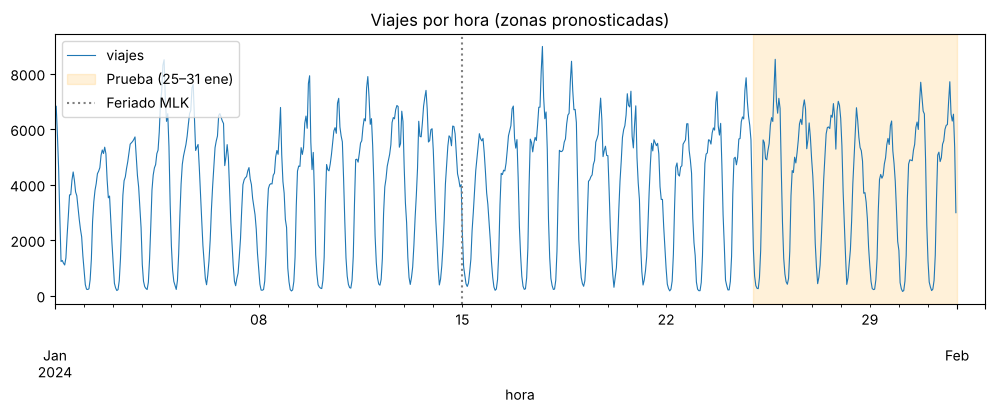

In [5]:
total_hora = serie.groupby("hora")["viajes"].sum(min_count=1)
fig, ax = plt.subplots(figsize=(12, 3.5))
total_hora.plot(ax=ax, lw=0.8)
ax.axvspan(INICIO_PRUEBA, FIN_PRUEBA, color="orange", alpha=0.15, label="Prueba (25–31 ene)")
ax.axvline(pd.Timestamp("2024-01-15"), color="gray", ls=":", label="Feriado MLK")
ax.set_title("Viajes por hora (zonas pronosticadas)")
ax.legend()
plt.show()

## 3. Variables: lags y calendario

El pronóstico se hace **el día anterior para todo el día siguiente**, por eso el lag más corto es de 24 horas.
Usar `lag_1` sería fuga de datos: a las 18:00 de mañana no se conocen los viajes de las 17:00 de mañana.

Los lags se calculan con `groupby("PULocationID").shift(...)` para no mezclar zonas.

In [6]:
g = serie.groupby("PULocationID")["viajes"]
for lag in (24, 48, 167, 168, 169):
    serie[f"lag_{lag}"] = g.shift(lag)

# Promedio de viajes por hora del día anterior (de la misma zona)
serie["fecha"] = serie["hora"].dt.normalize()
diario = serie.groupby(["PULocationID", "fecha"])["viajes"].mean().rename("media_dia_ant").reset_index()
diario["fecha"] = diario["fecha"] + pd.Timedelta(days=1)  # el promedio de ayer se usa hoy
serie = serie.merge(diario, on=["PULocationID", "fecha"], how="left")

serie["hora_dia"] = serie["hora"].dt.hour
serie["dia_semana"] = serie["hora"].dt.dayofweek          # 0 = lunes
serie["fin_semana"] = (serie["dia_semana"] >= 5).astype(int)
serie["feriado"] = serie["hora"].dt.date.isin(FERIADOS).astype(int)
serie["zona"] = pd.Categorical(serie["PULocationID"], categories=ZONAS_PRONOSTICO)

VARIABLES = ["lag_24", "lag_48", "lag_167", "lag_168", "lag_169", "media_dia_ant",
             "hora_dia", "dia_semana", "fin_semana", "feriado", "zona"]
serie[["PULocationID", "hora", "viajes"] + VARIABLES].tail(3)

,PULocationID,hora,viajes,lag_24,lag_48,lag_167,lag_168,lag_169,media_dia_ant,hora_dia,dia_semana,fin_semana,feriado,zona
44541,263,2024-02-01 21:00:00,NaN,92.0,96.0,85.0,104.0,110.0,80.833333,21,3,0,0,263
44542,263,2024-02-01 22:00:00,NaN,80.0,63.0,66.0,85.0,104.0,80.833333,22,3,0,0,263
44543,263,2024-02-01 23:00:00,NaN,53.0,42.0,36.0,66.0,85.0,80.833333,23,3,0,0,263


### División por tiempo (nunca `train_test_split`)

- **Entrenamiento:** del 8 al 24 de enero (antes del 8 no existe `lag_168`).
- **Validación interna** para elegir hiperparámetros: entrenar del 8 al 17 y validar del 18 al 24.
- **Prueba:** del 25 al 31 de enero. El modelo nunca la ve al entrenar.
- **Mañana:** 1 de febrero, sin valor real.

In [7]:
INICIO_ENTRENAMIENTO = pd.Timestamp("2024-01-08")
entreno = serie[(serie["hora"] >= INICIO_ENTRENAMIENTO) & (serie["hora"] < FIN_ENTRENAMIENTO)]
prueba = serie[(serie["hora"] >= INICIO_PRUEBA) & (serie["hora"] < FIN_PRUEBA)].copy()
manana = serie[serie["hora"] >= MANANA].copy()
print(f"Entrenamiento: {len(entreno):,} filas | Prueba: {len(prueba):,} | Mañana: {len(manana):,}")

Entrenamiento: 23,664 filas | Prueba: 9,744 | Mañana: 1,392


## 4. Modelo de cuantiles con XGBoost

Con `objective="reg:quantileerror"` y `quantile_alpha=[0.1, …, 0.9]` un solo modelo entrega los 9 cuantiles.
La pérdida que optimiza es la **pinball loss**, que castiga distinto quedarse corto y pasarse según el cuantil.

**Transformación logarítmica del objetivo.** Hay zonas con 5 viajes por hora y otras con 600. Entrenamos sobre
`log1p(viajes)` para que todas queden en una escala parecida, y al predecir volvemos con `expm1`.
Esto es válido para cuantiles: si una transformación es creciente, el cuantil 80% de `log1p(y)` transformado de vuelta
**es** el cuantil 80% de `y`. (En la validación por tiempo mejoró la pinball loss y la cobertura frente a entrenar sin log.)

In [8]:
def pinball(real, pred, cuantiles=CUANTILES):
    """Pérdida pinball promedio sobre todos los cuantiles (pred: n x q)."""
    real = np.asarray(real)[:, None]
    dif = real - pred
    return float(np.mean(np.maximum(cuantiles * dif, (cuantiles - 1) * dif)))


def crear_modelo(n_estimators=250, max_depth=5, learning_rate=0.05):
    return xgb.XGBRegressor(
        objective="reg:quantileerror", quantile_alpha=CUANTILES,
        n_estimators=n_estimators, max_depth=max_depth, learning_rate=learning_rate,
        subsample=0.9, colsample_bytree=0.9, min_child_weight=5,
        tree_method="hist", enable_categorical=True, max_cat_to_onehot=1,
        random_state=SEMILLA, n_jobs=-1,
    )


def entrenar(datos, **cfg):
    return crear_modelo(**cfg).fit(datos[VARIABLES], np.log1p(datos["viajes"]))


def predecir(modelo, datos):
    # np.sort evita cuantiles cruzados (p60 < p50); expm1 deshace el log1p; recortamos en 0 (no hay viajes negativos)
    return np.clip(np.expm1(np.sort(modelo.predict(datos[VARIABLES]), axis=1)), 0, None)

In [9]:
# Validación por tiempo para elegir hiperparámetros
CORTE_VALID = pd.Timestamp("2024-01-18")
tr_v = entreno[entreno["hora"] < CORTE_VALID]
va_v = entreno[entreno["hora"] >= CORTE_VALID]

configs = [dict(n_estimators=250, max_depth=4), dict(n_estimators=250, max_depth=5), dict(n_estimators=250, max_depth=6)]
resultados_valid = []
for cfg in configs:
    m = entrenar(tr_v, **cfg)
    p = predecir(m, va_v)
    resultados_valid.append({**cfg, "pinball": pinball(va_v["viajes"], p),
                             "MAE_p50": float(np.mean(np.abs(va_v["viajes"] - p[:, 4])))})
resultados_valid = pd.DataFrame(resultados_valid).sort_values("pinball")
mejor = resultados_valid.iloc[0][["n_estimators", "max_depth"]].astype(int).to_dict()
print("Mejor configuración (menor pinball en validación):", mejor)
resultados_valid

Mejor configuración (menor pinball en validación): {'n_estimators': 250, 'max_depth': 6}


,n_estimators,max_depth,pinball,MAE_p50
2,250,6,5.751784,14.683341
1,250,5,5.895956,15.105724
0,250,4,6.098875,15.527976


In [10]:
modelo = entrenar(entreno, **mejor)
pred_prueba = predecir(modelo, prueba)
for i, nombre in enumerate(NOMBRES_Q):
    prueba[nombre] = pred_prueba[:, i]
prueba[NOMBRES_Q].describe().T[["mean", "min", "max"]]

,mean,min,max
p10,42.502918,0.000000,230.669113
p20,55.697315,0.000000,409.774933
p30,60.567638,0.000000,454.905426
p40,64.743523,0.000000,489.515320
p50,68.783806,0.000000,532.978699
p60,73.177750,0.067916,571.390320
p70,77.861244,0.370837,627.898987
p80,83.478668,0.655960,680.594910
p90,92.587410,1.720757,712.350891


### Evaluación en la semana de prueba (25–31 de enero)

Comparamos la mediana (p50) del modelo contra dos reglas simples:
- **"Igual que hace una semana"** (`lag_168`)
- **"Igual que ayer"** (`lag_24`)

Métricas: **MAE** (error absoluto medio, en viajes por hora) y **WAPE** (error absoluto total / viajes totales).
Además medimos la **cobertura del rango del 80%** (p10–p90): debería contener cerca del 80% de los valores reales.

In [11]:
def wape(real, pred):
    return float(np.sum(np.abs(real - pred)) / np.sum(real))


def mae(real, pred):
    return float(np.mean(np.abs(real - pred)))


real = prueba["viajes"].values
comparacion = pd.DataFrame({
    "Método": ["Modelo XGBoost (p50)", "Igual que hace una semana", "Igual que ayer"],
    "MAE": [mae(real, prueba["p50"]), mae(real, prueba["lag_168"]), mae(real, prueba["lag_24"])],
    "WAPE": [wape(real, prueba["p50"]), wape(real, prueba["lag_168"]), wape(real, prueba["lag_24"])],
})
cobertura_80 = float(np.mean((real >= prueba["p10"]) & (real <= prueba["p90"])))
pinball_prueba = pinball(real, pred_prueba)
mejora_vs_semana = 1 - comparacion.loc[0, "MAE"] / comparacion.loc[1, "MAE"]
print(f"Cobertura del rango 80% (p10–p90): {cobertura_80:.1%}")
print(f"Pinball promedio: {pinball_prueba:.2f}")
print(f"Mejora del MAE frente a 'igual que hace una semana': {mejora_vs_semana:.1%}")
comparacion.style.format({"MAE": "{:.2f}", "WAPE": "{:.1%}"})

Cobertura del rango 80% (p10–p90): 87.6%
Pinball promedio: 4.66
Mejora del MAE frente a 'igual que hace una semana': 0.9%


,Método,MAE,WAPE
0,Modelo XGBoost (p50),11.77,16.6%
1,Igual que hace una semana,11.88,16.8%
2,Igual que ayer,21.29,30.1%


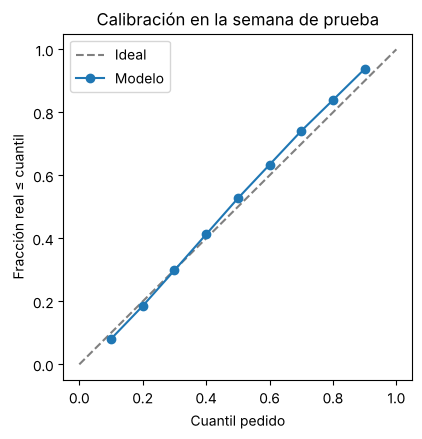

,cuantil,nombre,fraccion_real_debajo
0,0.1,p10,0.080768
1,0.2,p20,0.185447
2,0.3,p30,0.298543
3,0.4,p40,0.412767
4,0.5,p50,0.526888
5,0.6,p60,0.633826
6,0.7,p70,0.740969
7,0.8,p80,0.839080
8,0.9,p90,0.937808


In [12]:
# Calibración: ¿qué fracción de valores reales queda por debajo de cada cuantil? (ideal: igual al cuantil)
calibracion = pd.DataFrame({
    "cuantil": CUANTILES,
    "nombre": NOMBRES_Q,
    "fraccion_real_debajo": [float(np.mean(real <= prueba[n])) for n in NOMBRES_Q],
})
fig, ax = plt.subplots(figsize=(4.5, 4.5))
ax.plot([0, 1], [0, 1], "--", color="gray", label="Ideal")
ax.plot(calibracion["cuantil"], calibracion["fraccion_real_debajo"], "o-", label="Modelo")
ax.set_xlabel("Cuantil pedido"); ax.set_ylabel("Fracción real ≤ cuantil"); ax.set_title("Calibración en la semana de prueba")
ax.legend(); plt.show()
calibracion

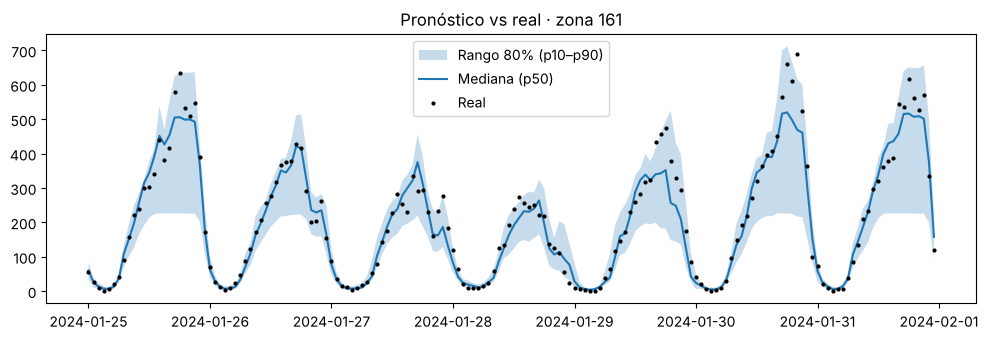

In [13]:
# Ejemplo: Midtown Center (161) en la semana de prueba
ej = prueba[prueba["PULocationID"] == 161] if 161 in ZONAS_PRONOSTICO else prueba[prueba["PULocationID"] == ZONAS_PRONOSTICO[0]]
fig, ax = plt.subplots(figsize=(12, 3.5))
ax.fill_between(ej["hora"], ej["p10"], ej["p90"], alpha=0.25, label="Rango 80% (p10–p90)")
ax.plot(ej["hora"], ej["p50"], label="Mediana (p50)")
ax.plot(ej["hora"], ej["viajes"], ".", color="black", ms=4, label="Real")
ax.set_title(f"Pronóstico vs real · zona {ej['PULocationID'].iloc[0]}")
ax.legend(); plt.show()

### Importancia de variables

La importancia por **ganancia** (`gain`) mide cuánto mejora la pérdida, en promedio, cada vez que el modelo divide
por esa variable. Nos dice en qué se apoya el pronóstico.

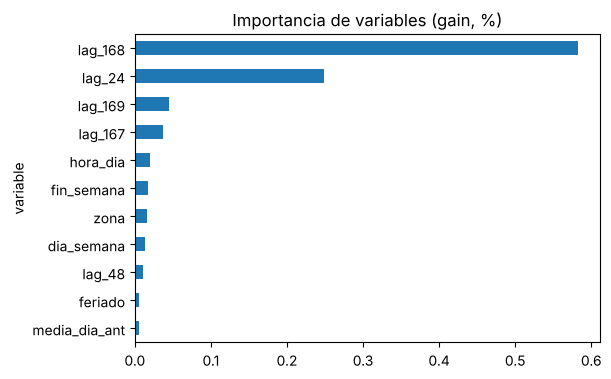

,ganancia,porcentaje
variable,,
lag_168,61.881901,0.582207
lag_24,26.375292,0.248148
lag_169,4.700332,0.044222
lag_167,3.917604,0.036858
hora_dia,2.090979,0.019673
fin_semana,1.851491,0.017419
zona,1.626279,0.015301
dia_semana,1.478742,0.013913
lag_48,1.204193,0.011329


In [14]:
imp = modelo.get_booster().get_score(importance_type="gain")
importancia = (pd.Series(imp).reindex(VARIABLES).fillna(0).rename("ganancia").to_frame()
               .assign(porcentaje=lambda d: d["ganancia"] / d["ganancia"].sum())
               .sort_values("porcentaje", ascending=False))
importancia.index.name = "variable"
importancia["porcentaje"].sort_values().plot.barh(figsize=(6, 4), title="Importancia de variables (gain, %)")
plt.show()
importancia

## 5. Guardar el modelo y las filas que necesita la API

La API **no recalcula los lags**: guardamos en `demanda.parquet` las filas del 25 de enero al 1 de febrero con sus
variables ya calculadas, el valor real (vacío el 1 de febrero) y el de hace una semana.

In [15]:
modelo.save_model(API / "modelo_pronostico.ubj")
tam_mb = (API / "modelo_pronostico.ubj").stat().st_size / 1e6
print(f"Modelo guardado: {tam_mb:.1f} MB (límite web de GitHub: 25 MB)")

nombres_zona = zonas.set_index("zona_id")
demanda = serie[serie["hora"] >= INICIO_PRUEBA].copy()
demanda["zona_nombre"] = demanda["PULocationID"].map(nombres_zona["nombre"])
demanda["distrito"] = demanda["PULocationID"].map(nombres_zona["distrito"])
demanda["hace_una_semana"] = demanda["lag_168"]
COLS_API = ["PULocationID", "zona_nombre", "distrito", "hora", "viajes", "hace_una_semana"] + [v for v in VARIABLES if v != "zona"]
demanda[COLS_API].to_parquet(API / "demanda.parquet", index=False)

meta_api = {"variables": VARIABLES, "categorias_zona": [int(z) for z in ZONAS_PRONOSTICO],
            "cuantiles": NOMBRES_Q, "fecha_entrenamiento_hasta": "2024-01-24",
            "parametros": {k: int(v) for k, v in mejor.items()}, "transformacion": "log1p",
            "xgboost_version": xgb.__version__}
(API / "meta_modelo.json").write_text(json.dumps(meta_api, indent=2), encoding="utf-8")
print("demanda.parquet:", demanda.shape, "| fechas:", demanda["hora"].dt.date.min(), "→", demanda["hora"].dt.date.max())

Modelo guardado: 15.4 MB (límite web de GitHub: 25 MB)
demanda.parquet: (11136, 18) | fechas: 2024-01-25 → 2024-02-01


## 6. Segmentación de zonas con K-Means y PCA

Una fila por zona (zonas con ≥ 500 viajes). Variables que describen **cómo se usa** cada zona:

| Variable | Por qué |
|---|---|
| `log_viajes_dia` | Volumen (en log: hay zonas con decenas y otras con miles de viajes por día) |
| `distancia_mediana`, `tarifa_mediana`, `propina_mediana` | Tipo de viaje (aeropuertos = largos y caros) |
| `pct_fin_semana` | Ocio vs trabajo |
| `pct_manana` (6–10 h), `pct_tarde` (16–20 h), `pct_noche` (22–5 h) | Patrón horario |

Para distancia, tarifa y propina descartamos antes los viajes con distancia o tarifa ≤ 0.

In [16]:
seg = viajes[viajes["PULocationID"].isin(ZONAS_SEGMENTO)].copy()
h = seg["tpep_pickup_datetime"].dt.hour
seg["es_finde"] = seg["tpep_pickup_datetime"].dt.dayofweek >= 5
seg["es_manana"] = h.between(6, 9)        # 6:00–9:59
seg["es_tarde"] = h.between(16, 19)       # 16:00–19:59
seg["es_noche"] = (h >= 22) | (h < 5)     # 22:00–4:59
seg["h"] = h

perfil = seg.groupby("PULocationID").agg(
    viajes=("h", "size"), pct_fin_semana=("es_finde", "mean"), pct_manana=("es_manana", "mean"),
    pct_tarde=("es_tarde", "mean"), pct_noche=("es_noche", "mean"))
perfil["viajes_dia"] = perfil["viajes"] / 31
perfil["log_viajes_dia"] = np.log10(perfil["viajes_dia"])

validos = seg[(seg["trip_distance"] > 0) & (seg["fare_amount"] > 0)]
perfil = perfil.join(validos.groupby("PULocationID").agg(
    distancia_mediana=("trip_distance", "median"), tarifa_mediana=("fare_amount", "median"),
    propina_mediana=("tip_amount", "median")))

# Perfil horario (proporción de viajes en cada hora) para el mini gráfico de la app
perfil_horario = (seg.groupby(["PULocationID", "h"]).size().unstack(fill_value=0)
                  .reindex(columns=range(24), fill_value=0))
perfil_horario = perfil_horario.div(perfil_horario.sum(axis=1), axis=0)

VARS_SEG = ["log_viajes_dia", "distancia_mediana", "tarifa_mediana", "propina_mediana",
            "pct_fin_semana", "pct_manana", "pct_tarde", "pct_noche"]
perfil = perfil.dropna(subset=VARS_SEG)
X = StandardScaler().fit_transform(perfil[VARS_SEG])
print("Zonas a segmentar:", len(perfil))
perfil[VARS_SEG].describe().T[["mean", "min", "max"]].round(2)

Zonas a segmentar: 100


,mean,min,max
log_viajes_dia,2.36,1.21,3.67
distancia_mediana,3.43,1.23,17.45
tarifa_mediana,20.11,10.00,70.00
propina_mediana,1.97,0.00,10.05
pct_fin_semana,0.26,0.10,0.55
pct_manana,0.17,0.03,0.52
pct_tarde,0.22,0.07,0.37
pct_noche,0.19,0.02,0.70


### ¿Cuántos grupos? Coeficiente de silueta para k = 2 a 7

La silueta va de −1 a 1: mide qué tan cerca está cada zona de su grupo comparado con el grupo vecino.
Elegimos el k con la **mayor silueta**. Además revisamos la inercia (método del codo) como apoyo y que los grupos
resultantes tengan un perfil interpretable para planificar.

k elegido: 4


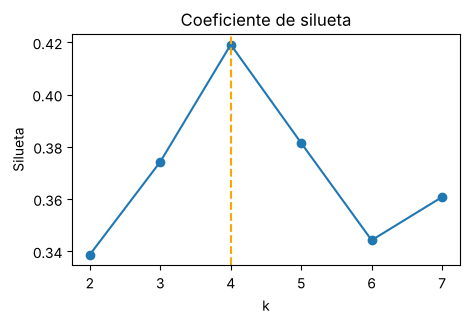

,k,silueta,inercia
0,2,0.338717,560.698167
1,3,0.374275,410.683881
2,4,0.419139,276.289288
3,5,0.381453,231.906050
4,6,0.344224,206.962155
5,7,0.360785,184.135424


In [17]:
silueta = []
for k in range(2, 8):
    km = KMeans(n_clusters=k, n_init=20, random_state=SEMILLA).fit(X)
    silueta.append({"k": k, "silueta": float(silhouette_score(X, km.labels_)), "inercia": float(km.inertia_)})
silueta = pd.DataFrame(silueta)
K = int(silueta.sort_values("silueta", ascending=False).iloc[0]["k"])
print("k elegido:", K)

fig, ax = plt.subplots(figsize=(5, 3))
ax.plot(silueta["k"], silueta["silueta"], "o-"); ax.axvline(K, color="orange", ls="--")
ax.set_xlabel("k"); ax.set_ylabel("Silueta"); ax.set_title("Coeficiente de silueta"); plt.show()
silueta

In [18]:
km = KMeans(n_clusters=K, n_init=50, random_state=SEMILLA).fit(X)
perfil["cluster"] = km.labels_

pca = PCA(n_components=2, random_state=SEMILLA)
componentes = pca.fit_transform(X)
perfil["pc1"], perfil["pc2"] = componentes[:, 0], componentes[:, 1]
var_pca = pca.explained_variance_ratio_
print(f"Variación conservada por PCA: PC1 {var_pca[0]:.1%} + PC2 {var_pca[1]:.1%} = {var_pca.sum():.1%}")

cargas = pd.DataFrame(pca.components_.T, index=VARS_SEG, columns=["PC1", "PC2"]).round(2)
cargas

Variación conservada por PCA: PC1 37.5% + PC2 27.4% = 64.9%


,PC1,PC2
log_viajes_dia,0.50,-0.14
distancia_mediana,-0.34,-0.06
tarifa_mediana,-0.35,-0.03
propina_mediana,0.29,-0.12
pct_fin_semana,0.16,0.61
pct_manana,-0.45,-0.25
pct_tarde,0.44,-0.32
pct_noche,0.02,0.65


### Nombrar los grupos según su perfil (no a mano por número)

K-Means numera los grupos al azar. Por eso los nombres salen de reglas sobre el **perfil promedio** de cada grupo,
aplicadas en orden y sin repetir grupo:

1. El grupo con **mayor distancia mediana** → *Aeropuertos y viajes largos*
2. De los restantes, el de **mayor volumen** → *Centro de alta demanda*
3. De los restantes, el de **menor volumen** → *Residencial de baja demanda*
4. De los restantes, el de **mayor % nocturno** → *Vida nocturna*
5. De los restantes, el de **mayor % fin de semana** → *Ocio de fin de semana*
6. De los restantes, el de **mayor % de 6 a 10 h** → *Residencial de horas pico*
7. Cualquier otro → *Uso mixto*

In [19]:
perfil_grupo = perfil.groupby("cluster")[VARS_SEG + ["viajes_dia"]].mean()
REGLAS = [("Aeropuertos y viajes largos", "distancia_mediana", "max"),
          ("Centro de alta demanda", "log_viajes_dia", "max"),
          ("Residencial de baja demanda", "log_viajes_dia", "min"),
          ("Vida nocturna", "pct_noche", "max"),
          ("Ocio de fin de semana", "pct_fin_semana", "max"),
          ("Residencial de horas pico", "pct_manana", "max")]

nombre_grupo, restantes = {}, list(perfil_grupo.index)
for nombre, var, sentido in REGLAS:
    if not restantes:
        break
    sub = perfil_grupo.loc[restantes, var]
    elegido = sub.idxmax() if sentido == "max" else sub.idxmin()
    nombre_grupo[elegido] = nombre
    restantes.remove(elegido)
for c in restantes:
    nombre_grupo[c] = f"Uso mixto {c}"

# Descripción automática: las 3 variables más distintas al promedio general (en desviaciones estándar)
ETIQUETAS = {"log_viajes_dia": "volumen de viajes", "distancia_mediana": "distancia", "tarifa_mediana": "tarifa",
             "propina_mediana": "propina", "pct_fin_semana": "% en fin de semana", "pct_manana": "% de 6 a 10 h",
             "pct_tarde": "% de 16 a 20 h", "pct_noche": "% de 22 a 5 h"}
z_grupo = pd.DataFrame(X, index=perfil.index, columns=VARS_SEG).groupby(perfil["cluster"]).mean()
descripciones = {}
for c in z_grupo.index:
    top = z_grupo.loc[c].abs().sort_values(ascending=False).index[:3]
    partes = [f"{'más' if z_grupo.loc[c, v] > 0 else 'menos'} {ETIQUETAS[v]} que el promedio" for v in top]
    descripciones[c] = "Se distingue por " + ", ".join(partes[:-1]) + " y " + partes[-1] + "."

perfil["grupo"] = perfil["cluster"].map(nombre_grupo)
resumen_grupos = perfil_grupo.assign(grupo=perfil_grupo.index.map(nombre_grupo),
                                     zonas=perfil.groupby("cluster").size(),
                                     descripcion=perfil_grupo.index.map(descripciones))
resumen_grupos[["grupo", "zonas", "viajes_dia", "distancia_mediana", "tarifa_mediana", "pct_fin_semana",
                "pct_manana", "pct_noche", "descripcion"]].round(2)

,grupo,zonas,viajes_dia,distancia_mediana,tarifa_mediana,pct_fin_semana,pct_manana,pct_noche,descripcion
cluster,,,,,,,,,
0,Aeropuertos y viajes largos,5,1603.64,11.96,58.18,0.27,0.13,0.17,"Se distingue por más propina que el promedio, ..."
1,Centro de alta demanda,47,1629.42,1.96,13.47,0.25,0.13,0.13,Se distingue por más % de 16 a 20 h que el pro...
2,Residencial de baja demanda,36,41.31,4.42,24.63,0.22,0.26,0.16,Se distingue por menos volumen de viajes que e...
3,Vida nocturna,12,700.20,2.64,16.73,0.44,0.07,0.48,Se distingue por más % de 22 a 5 h que el prom...


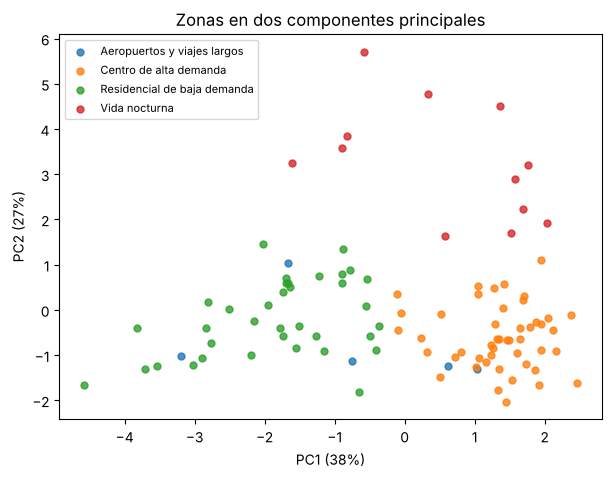

In [20]:
fig, ax = plt.subplots(figsize=(7, 5))
for nombre, d in perfil.groupby("grupo"):
    ax.scatter(d["pc1"], d["pc2"], label=nombre, s=25, alpha=0.8)
ax.set_xlabel(f"PC1 ({var_pca[0]:.0%})"); ax.set_ylabel(f"PC2 ({var_pca[1]:.0%})")
ax.set_title("Zonas en dos componentes principales"); ax.legend(fontsize=8); plt.show()

In [21]:
zonas_seg = perfil.reset_index().rename(columns={"PULocationID": "zona_id"})
zonas_seg = zonas_seg.merge(zonas[["zona_id", "nombre", "distrito"]], on="zona_id", how="left")
zonas_seg["pronosticable"] = zonas_seg["zona_id"].isin(ZONAS_PRONOSTICO)
zonas_seg["perfil_horario"] = zonas_seg["zona_id"].map(
    lambda z: json.dumps([round(float(v), 4) for v in perfil_horario.loc[z].values]))
COLS_SEG = ["zona_id", "nombre", "distrito", "grupo", "pc1", "pc2", "viajes", "viajes_dia"] + VARS_SEG + ["pronosticable", "perfil_horario"]
zonas_seg[COLS_SEG].to_csv(APP_DATA / "zonas_segmentadas.csv", index=False)
silueta.to_csv(APP_DATA / "silueta.csv", index=False)

meta_seg = {"k": K, "varianza_pca": [float(v) for v in var_pca], "variables": VARS_SEG,
            "grupos": {nombre_grupo[c]: {"descripcion": descripciones[c], "zonas": int((perfil["cluster"] == c).sum())}
                       for c in perfil_grupo.index},
            "cargas_pca": cargas.to_dict()}
(APP_DATA / "meta_segmentacion.json").write_text(json.dumps(meta_seg, indent=2, ensure_ascii=False), encoding="utf-8")
print("Guardado app/data/zonas_segmentadas.csv:", zonas_seg.shape)

Guardado app/data/zonas_segmentadas.csv: (100, 19)


## 7. Cifras para la ficha del modelo y para el monitoreo

Todas las cifras que muestra la página "Ficha del modelo" salen de esta sección.

### 7.1 ¿Dónde se equivoca más? Error por tipo de zona (une Parte 1 y Parte 2)

In [22]:
prueba["grupo"] = prueba["PULocationID"].map(perfil["grupo"])
prueba["err_modelo"] = (prueba["viajes"] - prueba["p50"]).abs()
prueba["err_semana"] = (prueba["viajes"] - prueba["lag_168"]).abs()
prueba["en_rango"] = (prueba["viajes"] >= prueba["p10"]) & (prueba["viajes"] <= prueba["p90"])

errores_grupo = prueba.groupby("grupo").agg(
    zonas=("PULocationID", "nunique"), viajes_hora=("viajes", "mean"),
    MAE_modelo=("err_modelo", "mean"), MAE_semana=("err_semana", "mean"),
    suma_err=("err_modelo", "sum"), suma_err_sem=("err_semana", "sum"), suma_real=("viajes", "sum"),
    cobertura_80=("en_rango", "mean")).reset_index()
errores_grupo["WAPE_modelo"] = errores_grupo["suma_err"] / errores_grupo["suma_real"]
errores_grupo["WAPE_semana"] = errores_grupo["suma_err_sem"] / errores_grupo["suma_real"]
errores_grupo = errores_grupo.drop(columns=["suma_err", "suma_err_sem", "suma_real"]).sort_values("WAPE_modelo", ascending=False)
errores_grupo.to_csv(APP_DATA / "errores_por_grupo.csv", index=False)
errores_grupo.round(3)

,grupo,zonas,viajes_hora,MAE_modelo,MAE_semana,cobertura_80,WAPE_modelo,WAPE_semana
2,Residencial de baja demanda,2,6.182,2.361,2.905,0.842,0.382,0.470
3,Vida nocturna,8,48.471,9.940,9.042,0.871,0.205,0.187
0,Aeropuertos y viajes largos,3,100.996,19.373,20.056,0.841,0.192,0.199
1,Centro de alta demanda,45,75.650,12.008,12.241,0.881,0.159,0.162


In [23]:
# Peores zonas (WAPE) y error por hora del día
err_zona = prueba.groupby("PULocationID").apply(
    lambda d: pd.Series({"WAPE_modelo": d["err_modelo"].sum() / max(d["viajes"].sum(), 1),
                         "WAPE_semana": d["err_semana"].sum() / max(d["viajes"].sum(), 1),
                         "viajes_hora": d["viajes"].mean(), "cobertura_80": d["en_rango"].mean()}),
    include_groups=False).reset_index().rename(columns={"PULocationID": "zona_id"})
err_zona = err_zona.merge(zonas[["zona_id", "nombre", "distrito"]], on="zona_id").merge(
    perfil["grupo"].rename_axis("zona_id").reset_index(), on="zona_id", how="left")
err_zona.sort_values("WAPE_modelo", ascending=False).to_csv(APP_DATA / "errores_por_zona.csv", index=False)

err_hora = prueba.groupby("hora_dia").agg(MAE_modelo=("err_modelo", "mean"), MAE_semana=("err_semana", "mean"),
                                         cobertura_80=("en_rango", "mean")).reset_index()
err_hora.to_csv(APP_DATA / "errores_por_hora.csv", index=False)
err_zona.sort_values("WAPE_modelo", ascending=False).head(8).round(3)

,zona_id,WAPE_modelo,WAPE_semana,viajes_hora,cobertura_80,nombre,distrito,grupo
0,4,0.507,0.508,6.345,0.821,Alphabet City,Manhattan,Vida nocturna
46,232,0.481,0.572,4.577,0.839,Two Bridges/Seward Park,Manhattan,Vida nocturna
4,42,0.478,0.622,4.048,0.833,Central Harlem North,Manhattan,Residencial de baja demanda
6,45,0.395,0.463,5.244,0.845,Chinatown,Manhattan,Centro de alta demanda
40,209,0.392,0.496,6.452,0.792,Seaport,Manhattan,Centro de alta demanda
42,224,0.390,0.494,5.548,0.839,Stuy Town/Peter Cooper Village,Manhattan,Centro de alta demanda
11,74,0.335,0.396,8.315,0.851,East Harlem North,Manhattan,Residencial de baja demanda
53,246,0.317,0.347,75.679,0.786,West Chelsea/Hudson Yards,Manhattan,Centro de alta demanda


### 7.2 Monitoreo: error día a día en la semana de prueba

In [24]:
prueba["fecha"] = prueba["hora"].dt.date.astype(str)
error_diario = prueba.groupby(["fecha", "PULocationID"]).agg(
    real=("viajes", "sum"), err_modelo=("err_modelo", "sum"), err_semana=("err_semana", "sum"),
    cobertura_80=("en_rango", "mean")).reset_index()
error_diario.to_csv(APP_DATA / "error_diario_zona.csv", index=False)

error_dia_total = error_diario.groupby("fecha").agg(real=("real", "sum"), err_modelo=("err_modelo", "sum"),
                                                    err_semana=("err_semana", "sum"),
                                                    cobertura_80=("cobertura_80", "mean")).reset_index()
error_dia_total["WAPE_modelo"] = error_dia_total["err_modelo"] / error_dia_total["real"]
error_dia_total["WAPE_semana"] = error_dia_total["err_semana"] / error_dia_total["real"]
error_dia_total.round(3)

,fecha,real,err_modelo,err_semana,cobertura_80,WAPE_modelo,WAPE_semana
0,2024-01-25,107641.0,14669.192,16042.0,0.899,0.136,0.149
1,2024-01-26,103023.0,15658.094,17525.0,0.876,0.152,0.170
2,2024-01-27,108142.0,20511.613,21437.0,0.849,0.190,0.198
3,2024-01-28,90342.0,19244.406,18881.0,0.831,0.213,0.209
4,2024-01-29,82177.0,16903.382,12202.0,0.866,0.206,0.148
5,2024-01-30,98993.0,14133.037,15035.0,0.896,0.143,0.152
6,2024-01-31,99719.0,13575.021,14654.0,0.915,0.136,0.147


### 7.3 Decisión: ¿cuánto se ahorra usando el cuantil óptimo?

Con un taxi ocioso a **$10/hora** y un pasajero perdido a **$40**, el cuantil óptimo es 40 / (40 + 10) = 0.80.
Comparamos el costo total de la semana de prueba (todas las zonas) de tres reglas.

In [25]:
C_OCIOSO, C_PERDIDO = 10, 40
q_opt = C_PERDIDO / (C_PERDIDO + C_OCIOSO)


def costo(enviados, real, c_o=C_OCIOSO, c_p=C_PERDIDO):
    return float(np.sum(np.maximum(enviados - real, 0) * c_o + np.maximum(real - enviados, 0) * c_p))


col_q = f"p{int(round(q_opt * 10)) * 10}"
costos = {"Cuantil óptimo (" + col_q + ")": costo(np.ceil(prueba[col_q]), real),
          "Pronóstico central (p50)": costo(np.round(prueba["p50"]), real),
          "Igual que hace una semana": costo(prueba["lag_168"], real)}
costos = pd.Series(costos, name="costo_semana_usd")
print(f"Ahorro del cuantil óptimo vs p50: {1 - costos.iloc[0] / costos.iloc[1]:.1%} | "
      f"vs hace una semana: {1 - costos.iloc[0] / costos.iloc[2]:.1%}")
costos.map("${:,.0f}".format)

Ahorro del cuantil óptimo vs p50: 29.5% | vs hace una semana: 29.5%


Cuantil óptimo (p80)         $2,229,360
Pronóstico central (p50)     $3,163,330
Igual que hace una semana    $3,160,950
Name: costo_semana_usd, dtype: str

### 7.4 Guardar las métricas

In [26]:
metricas = {
    "modelo": "XGBoost de cuantiles (reg:quantileerror) sobre log1p(viajes)", "parametros": {k: int(v) for k, v in mejor.items()},
    "entrenamiento": "8 al 24 de enero de 2024", "prueba": "25 al 31 de enero de 2024",
    "zonas_pronosticadas": len(ZONAS_PRONOSTICO), "zonas_segmentadas": len(perfil),
    "pct_viajes_cubiertos": float(viajes_por_zona[ZONAS_PRONOSTICO].sum() / len(viajes)),
    "filas_entrenamiento": int(len(entreno)), "filas_prueba": int(len(prueba)),
    "comparacion": comparacion.to_dict(orient="records"),
    "cobertura_80": cobertura_80, "pinball": pinball_prueba, "mejora_mae_vs_semana": float(mejora_vs_semana),
    "calibracion": calibracion.to_dict(orient="records"),
    "validacion": resultados_valid.to_dict(orient="records"),
    "costos_ejemplo": {"costo_ocioso": C_OCIOSO, "costo_perdido": C_PERDIDO, "cuantil": q_opt,
                       "totales": {k: float(v) for k, v in costos.items()}},
}
(APP_DATA / "metricas_modelo.json").write_text(json.dumps(metricas, indent=2, ensure_ascii=False), encoding="utf-8")
importancia.reset_index().to_csv(APP_DATA / "importancia_variables.csv", index=False)
error_dia_total.to_csv(APP_DATA / "error_diario.csv", index=False)
print("Archivos en app/data:", sorted(p.name for p in APP_DATA.iterdir()))
print("Archivos en api:", sorted(p.name for p in API.iterdir()))

Archivos en app/data: ['error_diario.csv', 'error_diario_zona.csv', 'errores_por_grupo.csv', 'errores_por_hora.csv', 'errores_por_zona.csv', 'importancia_variables.csv', 'meta_segmentacion.json', 'metricas_modelo.json', 'silueta.csv', 'zonas_segmentadas.csv']
Archivos en api: ['__pycache__', 'demanda.parquet', 'main.py', 'meta_modelo.json', 'modelo_pronostico.ubj', 'requirements.txt']


## 8. Conclusiones (para la ficha del modelo)

La celda siguiente imprime las conclusiones con las cifras de esta ejecución.

In [27]:
peor_g = errores_grupo.iloc[0]
mejor_g = errores_grupo.iloc[-1]
print(f"""- Modelo XGBoost de cuantiles entrenado del 8 al 24 de enero y evaluado POR TIEMPO con la semana del 25 al 31.
- MAE del modelo (p50): {comparacion.loc[0, 'MAE']:.2f} viajes/h vs {comparacion.loc[1, 'MAE']:.2f} de "igual que hace una semana"
  ({mejora_vs_semana:+.1%}) y {comparacion.loc[2, 'MAE']:.2f} de "igual que ayer".
  -> La demanda se repite mucho de una semana a otra; la ventaja de la mediana es {'pequeña' if mejora_vs_semana < 0.10 else 'clara'}.
- El rango del 80% (p10–p90) cubrió el {cobertura_80:.1%} de las horas: {'es algo conservador (ancho)' if cobertura_80 > 0.83 else 'está bien calibrado' if cobertura_80 >= 0.77 else 'es algo estrecho'}.
- Con costos de $10 (taxi ocioso) y $40 (pasajero perdido), enviar el cuantil p80 cuesta
  {1 - costos.iloc[0] / costos.iloc[1]:.0%} menos que enviar la mediana y {1 - costos.iloc[0] / costos.iloc[2]:.0%} menos que "igual que hace una semana".
  -> El valor principal del modelo está en el rango de incertidumbre, que la regla simple no da.
- Mayor error relativo: {peor_g['grupo']} (WAPE {peor_g['WAPE_modelo']:.0%}); menor: {mejor_g['grupo']} (WAPE {mejor_g['WAPE_modelo']:.0%}).
- La variable más importante es {importancia.index[0]} ({importancia['porcentaje'].iloc[0]:.0%} de la ganancia).
- Limitación clave: un solo mes de datos; no ve clima, eventos ni vuelos; cuenta viajes, no demanda insatisfecha.""")

- Modelo XGBoost de cuantiles entrenado del 8 al 24 de enero y evaluado POR TIEMPO con la semana del 25 al 31.
- MAE del modelo (p50): 11.77 viajes/h vs 11.88 de "igual que hace una semana"
  (+0.9%) y 21.29 de "igual que ayer".
  -> La demanda se repite mucho de una semana a otra; la ventaja de la mediana es pequeña.
- El rango del 80% (p10–p90) cubrió el 87.6% de las horas: es algo conservador (ancho).
- Con costos de $10 (taxi ocioso) y $40 (pasajero perdido), enviar el cuantil p80 cuesta
  30% menos que enviar la mediana y 29% menos que "igual que hace una semana".
  -> El valor principal del modelo está en el rango de incertidumbre, que la regla simple no da.
- Mayor error relativo: Residencial de baja demanda (WAPE 38%); menor: Centro de alta demanda (WAPE 16%).
- La variable más importante es lag_168 (58% de la ganancia).
- Limitación clave: un solo mes de datos; no ve clima, eventos ni vuelos; cuenta viajes, no demanda insatisfecha.
